## This code implements and simulates an LQR controller for a Furuta Pendulum about the upright equilibrium. The simulated responses are compared with experimental data, and the results are plotted for analysis.

In [18]:
# =========================
# Library imports
# =========================

import numpy as np # Numerical operations and matrix manipulation
import control as ctrl # Control systems library
import matplotlib.pyplot as plt # Plotting and visualization library


# =========================
# Figure formatting setup
# =========================

# Configures default plot appearance
plt.rcParams.update({

    # Uses serif fonts in all figures
    "font.family": "serif",

    # Sets Times New Roman as the main font
    "font.serif": ["Times New Roman"],

    # Uses STIX fonts for mathematical expressions
    "mathtext.fontset": "stix",

    # Ensures editable text in exported PDF files
    "pdf.fonttype": 42
})

### Development of the linear model and LQR controller for the Furuta Pendulum system.

In [19]:
# =========================
# System parameters
# =========================

g  = 9.8      # Gravity acceleration (m/s²)
m1 = 0.085    # Mass of arm 1 (kg)
m2 = 0.023    # Mass of arm 2 (kg)
L1 = 0.046    # Length of arm 1 (m)
l1 = 0.023    # Distance to CM of arm 1 (m)
l2 = 0.064    # Distance to CM of arm 2 (m)
b1 = 8.2e-05  # Viscous friction coefficient 1
b2 = 2.1e-05  # Viscous friction coefficient 2
c1 = 0.0065   # Motor torque constant 1
c2 = 0.00035  # Motor torque constant 2
I1 = 3.9e-5   # Moment of inertia 1 (kg.m²)
I2 = 2.5e-5   # Base moment of inertia 2 (kg.m²)


# =========================
# Auxiliary model constants
# =========================

# Moments of inertia updated with parallel axis theorem
I2 = I2 + m2 * l2**2
I0 = I1 + m1 * l1**2 + m2 * L1**2
Kc = L1 * l2 * m2

den = (I0 * I2 - Kc**2)

# Linearized state-space coefficients
A32 = (Kc * g * l2 * m2) / den
A33 = -(I2 * (c2 + b1)) / den
A34 = -(Kc * b2) / den

A42 = (I0 * g * l2 * m2) / den
A43 = -(Kc * (c2 + b1)) / den
A44 = -(I0 * b2) / den

B31 = (c1 * I2) / den
B41 = (c1 * Kc) / den


# =========================
# State-space model
# =========================
# x = [theta1, theta2, theta1_dot, theta2_dot]

# State matrix
A = np.zeros((4, 4))
A[0, 2] = 1
A[1, 3] = 1
A[2, 1] = A32
A[2, 2] = A33
A[2, 3] = A34
A[3, 1] = A42
A[3, 2] = A43
A[3, 3] = A44

# Input matrix
B = np.array([[0],
              [0],
              [B31],
              [B41]])

# Output matrix (all states measured)
C = np.eye(4)

# Direct transmission matrix
D = np.zeros((4, 1))


# =========================
# LQR weighting matrices
# =========================

# State weighting matrix
Q = np.eye(4)

# Penalizes arm 1 angle (theta1)
Q[0, 0] = 0.4

# Penalizes pendulum angle (theta2)
Q[1, 1] = 30

# Penalizes arm 1 angular velocity (theta1_dot)
Q[2, 2] = 0.002

# Penalizes pendulum angular velocity (theta2_dot)
Q[3, 3] = 0.005

# Control effort weighting (R matrix)
R_lqr = np.array([[1]])


# =========================
# Continuous-time LQR
# =========================

# Computes optimal feedback gain
K, _, _ = ctrl.lqr(A, B, Q, R_lqr)

print("Continuous LQR Gain (K):")
print(K)


# =========================
# Discretization
# =========================

# Sampling time (s)
Ts = 0.01

# Converts continuous model to discrete model using Tustin (Bilinear) method
discrete_system = ctrl.c2d(ctrl.ss(A, B, C, D), Ts, method='tustin')

# Discrete matrices
A_d = discrete_system.A
B_d = discrete_system.B


# =========================
# Discrete-time LQR
# =========================

# Computes discrete optimal gain
K_d, _, _ = ctrl.dlqr(A_d, B_d, Q, R_lqr)

print("\nDiscrete LQR Gain (K_d):")
print(K_d)

Continuous LQR Gain (K):
[[-0.63245553 18.61764369 -0.36836511  1.48095674]]

Discrete LQR Gain (K_d):
[[-0.53714845 16.81764478 -0.32560565  1.34102685]]


### Nonlinear simulation of the Furuta Pendulum system under external disturbances and actuator saturation.

In [20]:
# =========================
# Nonlinear dynamics
# =========================
def nonlinear_dynamics(x, V):
    theta1, theta2, dtheta1, dtheta2 = x

    # Input torques
    tau1 = c1 * V - c2 * dtheta1
    tau2 = 0.0

    # Equivalent constants from MATLAB
    J2_hat = I2
    J0_hat = I0

    # Denominator (D)
    D = (
        J0_hat * J2_hat
        + J2_hat**2 * np.sin(theta2)**2
        - m2**2 * L1**2 * l2**2 * np.cos(theta2)**2
    )

    # Numerator for ddot_theta1
    Num1_term1 = np.array([
        -J2_hat * b1,
        m2 * L1 * l2 * np.cos(theta2) * b2,
        -J2_hat**2 * np.sin(2 * theta2),
        -0.5 * J2_hat * m2 * L1 * l2 * np.cos(theta2) * np.sin(2 * theta2),
        J2_hat * m2 * L1 * l2 * np.sin(theta2)
    ])
    Vec1_states = np.array([
        dtheta1,
        dtheta2,
        dtheta1 * dtheta2,
        dtheta1**2,
        dtheta2**2
    ])

    Num1_term2 = np.array([
        J2_hat,
        -m2 * L1 * l2 * np.cos(theta2),
        0.5 * m2**2 * l2**2 * L1 * np.sin(2 * theta2)
    ])
    Vec1_inputs = np.array([tau1, tau2, g])

    Num1 = np.dot(Num1_term1, Vec1_states) + np.dot(Num1_term2, Vec1_inputs)
    ddtheta1 = Num1 / D

    # Numerator for ddot_theta2
    Num2_term1 = np.array([
        m2 * L1 * l2 * np.cos(theta2) * b1,
        -b2 * (J0_hat + J2_hat * np.sin(theta2)**2),
        m2 * L1 * l2 * J2_hat * np.cos(theta2) * np.sin(2 * theta2),
        -0.5 * np.sin(2 * theta2) * (J0_hat * J2_hat + J2_hat**2 * np.sin(theta2)**2),
        -0.5 * m2**2 * L1**2 * l2**2 * np.sin(2 * theta2)
    ])
    Vec2_states = np.array([
        dtheta1,
        dtheta2,
        dtheta1 * dtheta2,
        dtheta1**2,
        dtheta2**2
    ])

    Num2_term2 = np.array([
        -m2 * L1 * l2 * np.cos(theta2),
        J0_hat + J2_hat * np.sin(theta2)**2,
        -m2 * l2 * np.sin(theta2) * (J0_hat + J2_hat * np.sin(theta2)**2)
    ])
    Vec2_inputs = np.array([tau1, tau2, g])

    Num2 = np.dot(Num2_term1, Vec2_states) + np.dot(Num2_term2, Vec2_inputs)
    ddtheta2 = Num2 / D

    return np.array([dtheta1, dtheta2, ddtheta1, ddtheta2])


# =========================
# Simulation
# =========================
def sat(V, Vmax=12.0):
    return np.clip(V, -Vmax, Vmax)


def pulse_disturbance(t):
    return 1.0 if 1.0 <= t <= 2.0 else 0.0


def step_disturbance(t):
    return 1.0 if t >= 1.0 else 0.0


def closed_loop_dynamics(t, x, disturbance_function):
    # State feedback vector
    x_ctrl = np.array([x[0], x[1] - np.pi, x[2], x[3]])

    # LQR control law
    u_lqr = -(K @ x_ctrl).item()

    # Disturbance
    d = disturbance_function(t)

    # Actuator saturation
    V_input = sat(u_lqr)

    # Plant dynamics
    dx = nonlinear_dynamics(x, V_input + d)
    return dx, V_input, d


# Computes one step of the 4th Order Runge-Kutta (RK4) integration method.
def rk4_step(t, x, h, disturbance_function):
    k1, u1, d1 = closed_loop_dynamics(t, x, disturbance_function)
    k2, _, _ = closed_loop_dynamics(t + 0.5 * h, x + 0.5 * h * k1, disturbance_function)
    k3, _, _ = closed_loop_dynamics(t + 0.5 * h, x + 0.5 * h * k2, disturbance_function)
    k4, _, _ = closed_loop_dynamics(t + h, x + h * k3, disturbance_function)

    x_next = x + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)
    return x_next, u1, d1


def simulate(disturbance_function):
    # Initial states [theta1, theta2, theta1_dot, theta2_dot]
    x = np.array([0.0, np.pi, 0.0, 0.0])

    # Storage
    theta1 = []
    theta2 = []
    dtheta1 = []
    dtheta2 = []
    u = []
    disturbance = []

    for ti in t:
        # Store current state before integration
        theta1.append(x[0])
        theta2.append(x[1] - np.pi)
        dtheta1.append(x[2])
        dtheta2.append(x[3])

        # One RK4 step
        x, u_current, d_current = rk4_step(ti, x, dt, disturbance_function)

        # Store input/disturbance
        u.append(u_current)
        disturbance.append(d_current)

    # Convert to numpy arrays
    theta1 = np.array(theta1)
    theta2 = np.array(theta2)
    dtheta1 = np.array(dtheta1)
    dtheta2 = np.array(dtheta2)
    u = np.array(u)
    disturbance = np.array(disturbance)

    # Convert angles and angular velocities to degrees
    theta1 = np.rad2deg(theta1)
    theta2 = np.rad2deg(theta2)
    dtheta1 = np.rad2deg(dtheta1)
    dtheta2 = np.rad2deg(dtheta2)

    return theta1, theta2, dtheta1, dtheta2, u, disturbance


T_final = 10  # Simulation time
dt = 0.001    # Simulation step
t = np.arange(0, T_final, dt)

# Pulse-disturbance simulation
theta1_p, theta2_p, dtheta1_p, dtheta2_p, u_p, disturbance_p = simulate(pulse_disturbance)

# Step-disturbance simulation
theta1_s, theta2_s, dtheta1_s, dtheta2_s, u_s, disturbance_s = simulate(step_disturbance)

### Comparison between experimental and simulated responses of the system under pulse disturbance conditions.

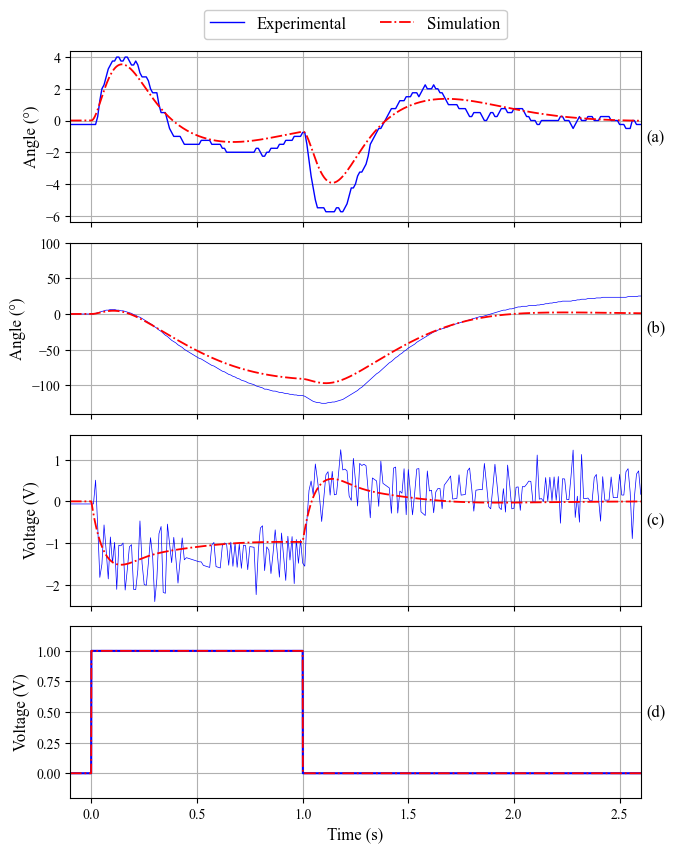

In [21]:
# =========================
# Experimental data - Pulse disturbance
# =========================

# Loads experimental data file
data_pulse = np.loadtxt('PulseData.txt')

# Plot limits
x_init = -0.1
x_final = 2.6

# Experimental signals
time_pulse = data_pulse[:, 0] - 20
theta1_pulse = data_pulse[:, 1] * 57.296
theta2_pulse = data_pulse[:, 2] * 57.296
theta1_dot_pulse = data_pulse[:, 3] * 57.296
theta2_dot_pulse = data_pulse[:, 4] * 57.296
input_signal_pulse = data_pulse[:, 5]
disturbance_pulse = data_pulse[:, 6]

# Simulation signals (Adjusted time)
time_sim = t[:len(theta1_p)] - 1.0

# =========================
# Combined figure: Pulse disturbance
# =========================

fig, ax = plt.subplots(4, 1, figsize=(7, 9), sharex=True)

# Pendulum angle comparison (theta2)
experimental_line, = ax[0].plot(time_pulse, theta2_pulse, 'b', linewidth=1)
simulation_line, = ax[0].plot(time_sim, theta2_p, '-.r', linewidth=1.3)
ax[0].set_ylabel('Angle (°)', fontsize=12)
ax[0].grid(True, alpha=1.0)
ax[0].set_xlim([x_init, x_final])
ax[0].set_ylim([-6.4, 4.4])
ax[0].text(1.01, 0.5, '(a)', transform=ax[0].transAxes, fontsize=12, va='center')

# Arm angle comparison (theta1)
ax[1].plot(time_pulse, theta1_pulse - theta1_pulse[np.argmin(np.abs(time_pulse))], 'b', linewidth=0.5)
ax[1].plot(time_sim, theta1_p, '-.r', linewidth=1.3)
ax[1].set_ylabel('Angle (°)', fontsize=12)
ax[1].grid(True, alpha=1.0)
ax[1].set_xlim([x_init, x_final])
ax[1].set_ylim([-140, 100])
ax[1].text(1.01, 0.5, '(b)', transform=ax[1].transAxes, fontsize=12, va='center')

# Control signal comparison
ax[2].plot(time_pulse, input_signal_pulse, 'b', linewidth=0.5)
ax[2].plot(time_sim, u_p, '-.r', linewidth=1.3)
ax[2].set_ylabel('Voltage (V)', fontsize=12)
ax[2].grid(True, alpha=1.0)
ax[2].set_xlim([x_init, x_final])
ax[2].set_ylim([-2.5, 1.6])
ax[2].text(1.01, 0.5, '(c)', transform=ax[2].transAxes, fontsize=12, va='center')

# Disturbance comparison
ax[3].plot(time_sim, disturbance_p, 'b', linewidth=1.5)
ax[3].plot(time_sim, disturbance_p, '-.r', linewidth=1.3)
ax[3].set_xlabel('Time (s)', fontsize=12)
ax[3].set_ylabel('Voltage (V)', fontsize=12)
ax[3].grid(True, alpha=1.0)
ax[3].set_xlim([x_init, x_final])
ax[3].set_ylim([-0.2, 1.2])
ax[3].text(1.01, 0.5, '(d)', transform=ax[3].transAxes, fontsize=12, va='center')

# Shared legend
fig.legend([experimental_line, simulation_line], ['Experimental', 'Simulation'], loc='upper center', ncol=2, fontsize=12, framealpha=1.0, bbox_to_anchor=(0.532, 0.995))

# Adjusts spacing and saves the figure
fig.subplots_adjust(top=0.94, hspace=0.12, right=0.94)
plt.savefig('pulse_disturbance.pdf', format='pdf', bbox_inches='tight', facecolor='white')

# Displays the figure
plt.show()

### Comparison between experimental and simulated responses of the system under step disturbance conditions.

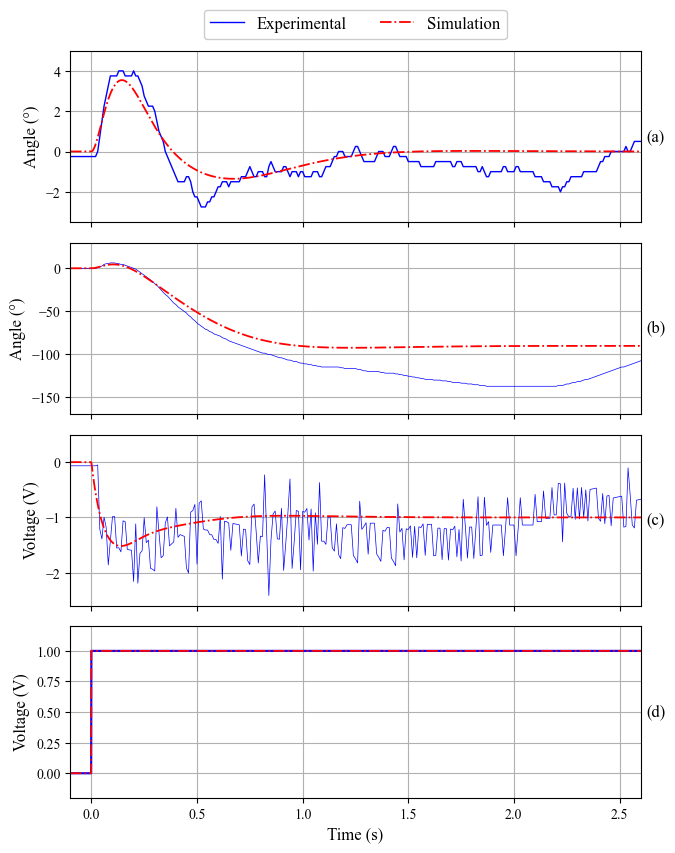

In [22]:
# =========================
# Experimental data - Step disturbance
# =========================

# Loads experimental data file
data_step = np.loadtxt('StepData.txt')

# Plot limits
x_init = -0.1
x_final = 2.6

# Experimental signals
time_step = data_step[:, 0] - 20
theta1_step = data_step[:, 1] * 57.296
theta2_step = data_step[:, 2] * 57.296 - 2
theta1_dot_step = data_step[:, 3] * 57.296
theta2_dot_step = data_step[:, 4] * 57.296
input_signal_step = data_step[:, 5]
disturbance_step = data_step[:, 6]

# Simulation signals (Adjusted time)
time_sim = t[:len(theta1_s)] - 1.0

# =========================
# Combined figure: Step disturbance
# =========================

fig, ax = plt.subplots(4, 1, figsize=(7, 9), sharex=True)

# Pendulum angle comparison (theta2)
experimental_line, = ax[0].plot(time_step, theta2_step, 'b', linewidth=1)
simulation_line, = ax[0].plot(time_sim, theta2_s, '-.r', linewidth=1.3)
ax[0].set_ylabel('Angle (°)', fontsize=12)
ax[0].grid(True, alpha=1.0)
ax[0].set_xlim([x_init, x_final])
ax[0].set_ylim([-3.5, 5])
ax[0].text(1.01, 0.5, '(a)', transform=ax[0].transAxes, fontsize=12, va='center')

# Arm angle comparison (theta1)
ax[1].plot(time_step, theta1_step - theta1_step[np.argmin(np.abs(time_step))], 'b', linewidth=0.5)
ax[1].plot(time_sim, theta1_s, '-.r', linewidth=1.3)
ax[1].set_ylabel('Angle (°)', fontsize=12)
ax[1].grid(True, alpha=1.0)
ax[1].set_xlim([x_init, x_final])
ax[1].set_ylim([-170, 30])
ax[1].text(1.01, 0.5, '(b)', transform=ax[1].transAxes, fontsize=12, va='center')

# Control signal comparison
ax[2].plot(time_step, input_signal_step, 'b', linewidth=0.5)
ax[2].plot(time_sim, u_s, '-.r', linewidth=1.3)
ax[2].set_ylabel('Voltage (V)', fontsize=12)
ax[2].grid(True, alpha=1.0)
ax[2].set_xlim([x_init, x_final])
ax[2].set_ylim([-2.6, 0.5])
ax[2].text(1.01, 0.5, '(c)', transform=ax[2].transAxes, fontsize=12, va='center')

# Disturbance comparison
ax[3].plot(time_sim, disturbance_s, 'b', linewidth=1.5)
ax[3].plot(time_sim, disturbance_s, '-.r', linewidth=1.3)
ax[3].set_xlabel('Time (s)', fontsize=12)
ax[3].set_ylabel('Voltage (V)', fontsize=12)
ax[3].grid(True, alpha=1.0)
ax[3].set_xlim([x_init, x_final])
ax[3].set_ylim([-0.2, 1.2])
ax[3].text(1.01, 0.5, '(d)', transform=ax[3].transAxes, fontsize=12, va='center')

# Shared legend
fig.legend([experimental_line, simulation_line], ['Experimental', 'Simulation'], loc='upper center', ncol=2, fontsize=12, framealpha=1.0, bbox_to_anchor=(0.532, 0.995))

# Adjusts spacing and saves the figure
fig.subplots_adjust(top=0.94, hspace=0.12, right=0.94)
plt.savefig('step_disturbance.pdf', format='pdf', bbox_inches='tight', facecolor='white')

# Displays the figure
plt.show()